# ISO 20414:2020 — Test 7: Overtaking People with Movement Disabilities

Two 4 m x 5 m rooms are joined by a 12 m x 1,5 m ramp with `speed_factor = 0.5` (ISO 20414:2020 Table 8). Room 1 has two zones. 24 occupants start in Zone 1 and move to the exit in room 2. In Zone 2 (x = 4.05 to 5.05 m, next to the ramp entrance) one extra occupant starts. In Scenario 1 this occupant is slow and large (e.g. a wheelchair user: `v0` 0.8 m/s, radius 0.4 m). In Scenario 2 the same occupant has the characteristics of the others (`v0` 1.25 m/s, radius 0.2 m).

Expected result: occupants in Zone 1 in Scenario 1 reach the exit more slowly than occupants in Zone 1 in Scenario 2. The acceptance criterion compares the **Zone 1 exit times** (last and mean), not the total evacuation time.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 09:14 CEST


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pedpy
from shapely.geometry import Point, Polygon

from jupedsim_scenarios import load_scenario, run_scenario

In [3]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f7f7f5",
    "axes.edgecolor": "#3a3a3a",
    "axes.labelcolor": "#1d1d1d",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "figure.figsize": (8, 5),
})

## Load and Run the Scenario 1

In [4]:
SCENARIO_ZIP_1 = Path("scenario_files") / "Iso-07-movement-disabilities.zip"
scenario_1 = load_scenario(str(SCENARIO_ZIP_1))
print(scenario_1.summary())
result_1 = run_scenario(scenario_1, seed=42)
walkable_1 = scenario_1.walkable_polygon
df1 = result_1.trajectory_dataframe()

Scenario: /private/tmp/claude-503/-Users-chraibi-workspace-PedestrianDynamics-jupedsim/e5d2f2d0-75c2-4b29-8ed9-ee0d37e131eb/scratchpad/zone1/standards/iso/scenario_files/Iso-07-movement-disabilities.zip
  Model:         CollisionFreeSpeedModel
  Seed:          42
  Max time:      300s
  Exits:         1
  Distributions: 2
  Stages:        0
  Zones:         1
  Journeys:      0
  Agents:        ~25
    jps-distributions_0: 24 agents
    jps-distributions_1: 1 agents


## Load and Run the Scenario 2

In [5]:
SCENARIO_ZIP_2 = Path("scenario_files") / "Iso-07-movement-disabilities-no-disability.zip"
scenario_2 = load_scenario(str(SCENARIO_ZIP_2))
print(scenario_2.summary())
result_2 = run_scenario(scenario_2, seed=42)
walkable_2 = scenario_2.walkable_polygon
df2 = result_2.trajectory_dataframe()

Scenario: /private/tmp/claude-503/-Users-chraibi-workspace-PedestrianDynamics-jupedsim/e5d2f2d0-75c2-4b29-8ed9-ee0d37e131eb/scratchpad/zone1/standards/iso/scenario_files/Iso-07-movement-disabilities-no-disability.zip
  Model:         CollisionFreeSpeedModel
  Seed:          42
  Max time:      300s
  Exits:         1
  Distributions: 2
  Stages:        0
  Zones:         1
  Journeys:      0
  Agents:        ~25
    jps-distributions_0: 24 agents
    jps-distributions_1: 1 agents


In [6]:
def agent_ids_by_start_zone(df, scenario):
    first_positions = (
        df.sort_values(["id", "frame"])
        .groupby("id", as_index=False)
        .first()
    )

    distributions = {
        name: Polygon(data["coordinates"])
        for name, data in scenario.raw["distributions"].items()
    }

    ids_by_zone = {name: set() for name in distributions}

    for row in first_positions.itertuples():
        start = Point(row.x, row.y)
        for name, polygon in distributions.items():
            if polygon.covers(start):
                ids_by_zone[name].add(row.id)
                break

    return ids_by_zone


zones_1 = agent_ids_by_start_zone(df1, scenario_1)
zones_2 = agent_ids_by_start_zone(df2, scenario_2)

zone1_ids_s1 = zones_1["jps-distributions_0"]
zone2_ids_s1 = zones_1["jps-distributions_1"]

zone1_ids_s2 = zones_2["jps-distributions_0"]
zone2_ids_s2 = zones_2["jps-distributions_1"]
def evacuation_times_by_agent(df, frame_rate):
    times = (
        df.groupby("id")["frame"]
        .max()
        .div(frame_rate)
        .rename("evacuation_time_s")
    )
    return times


agent_times_1 = evacuation_times_by_agent(df1, result_1.frame_rate)
agent_times_2 = evacuation_times_by_agent(df2, result_2.frame_rate)

zone1_evacuation_1 = agent_times_1.loc[list(zone1_ids_s1)].max()
zone1_evacuation_2 = agent_times_2.loc[list(zone1_ids_s2)].max()

In [7]:
comparison = pd.DataFrame(
    {
        "Scenario": [
            "Scenario 1 — movement disability",
            "Scenario 2 — no disability",
        ],
        "Total Evacuation Time (s)": [
            result_1.evacuation_time,
            result_2.evacuation_time,
        ],
    }
)
display(comparison.round(2))

,Scenario,Total Evacuation Time (s)
0,Scenario 1 — movement disability,50.21
1,Scenario 2 — no disability,41.37


## Plot Trajectories

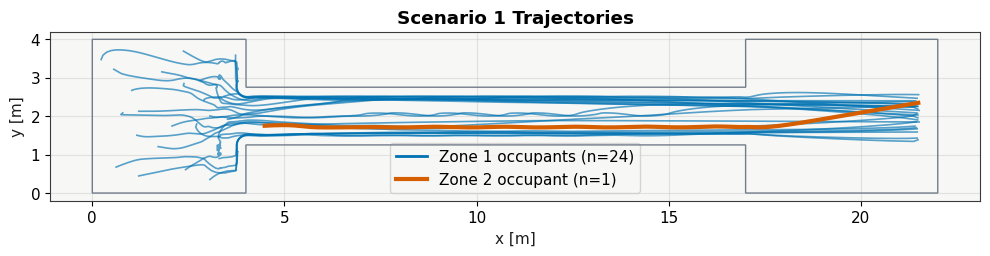

In [8]:
# Plot Scenario 1 trajectories, colored by starting zone
fig, ax = plt.subplots(figsize=(12, 5))

walkable_area = pedpy.WalkableArea(walkable_1)
pedpy.plot_walkable_area(walkable_area=walkable_area, axes=ax)

for agent_id, trajectory in (
    df1.sort_values(["id", "frame"]).groupby("id")
):
    if agent_id in zone2_ids_s1:
        color = "#D55E00"
        linewidth = 3.0
        alpha = 1.0
        zorder = 3
    else:
        color = "#0072B2"
        linewidth = 1.2
        alpha = 0.65
        zorder = 2

    ax.plot(
        trajectory["x"],
        trajectory["y"],
        color=color,
        linewidth=linewidth,
        alpha=alpha,
        zorder=zorder,
    )

# Legend handles
ax.plot(
    [], [],
    color="#0072B2",
    linewidth=2,
    label=f"Zone 1 occupants (n={len(zone1_ids_s1)})",
)
ax.plot(
    [], [],
    color="#D55E00",
    linewidth=3,
    label=f"Zone 2 occupant (n={len(zone2_ids_s1)})",
)

ax.set_title("Scenario 1 Trajectories")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_aspect("equal", adjustable="box")
ax.legend()
plt.show()

## Zone 1 Exit Times

In [9]:
# House style for the figures below (plain matplotlib: seaborn is not in this environment)
C_S1, C_S2 = "#d73027", "#4575b4"  # Scenario 1 (disability), Scenario 2 (no disability)
LEGEND = {"frameon": True, "facecolor": "white", "framealpha": 0.8, "edgecolor": "lightgrey", "labelcolor": "dimgrey"}
plt.rcParams.update({
    "figure.facecolor": "white", "figure.dpi": 100,
    "axes.facecolor": "white", "axes.grid": True, "grid.color": "#e0e0e0", "grid.alpha": 1.0,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "normal", "axes.titlecolor": "dimgrey", "axes.labelcolor": "dimgrey",
    "font.family": "DejaVu Sans", "font.size": 10,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "xtick.labelcolor": "dimgrey", "ytick.labelcolor": "dimgrey",
})


def frame_axes(ax):
    ax.patch.set_edgecolor("lightgrey")
    ax.patch.set_linewidth(0.8)

In [10]:
# Zone 1 exit times; exit time = last recorded frame / frame_rate
assert result_1.frame_rate == result_2.frame_rate
frame_rate = result_1.frame_rate
slow_id = next(iter(zone2_ids_s1))
extra_id_s2 = next(iter(zone2_ids_s2))
slow_exit = agent_times_1.loc[slow_id]
extra_exit = agent_times_2.loc[extra_id_s2]


def zone1_spawn_and_exit(df, ids, times):
    first = df[df["id"].isin(ids)].sort_values("frame").groupby("id").first()[["x", "y"]]
    first["exit_s"] = times.loc[first.index]
    return first.sort_values(["x", "y"])


# Agent ids differ between the two runs; the same 24 agents are matched by spawn position
z1_s1 = zone1_spawn_and_exit(df1, zone1_ids_s1, agent_times_1)
z1_s2 = zone1_spawn_and_exit(df2, zone1_ids_s2, agent_times_2)
np.testing.assert_allclose(z1_s1[["x", "y"]].to_numpy(), z1_s2[["x", "y"]].to_numpy(), atol=1e-6)
paired = pd.DataFrame({"exit_s1": z1_s1["exit_s"].to_numpy(), "exit_s2": z1_s2["exit_s"].to_numpy()})
ramp_x0, ramp_x1 = (
    min(c[0] for c in scenario_1.raw["zones"]["jps-zones_0"]["coordinates"]),
    max(c[0] for c in scenario_1.raw["zones"]["jps-zones_0"]["coordinates"]),
)
print(f"{len(paired)} paired Zone 1 agents; ramp x = {ramp_x0:.2f} to {ramp_x1:.2f} m")

24 paired Zone 1 agents; ramp x = 4.03 to 17.00 m


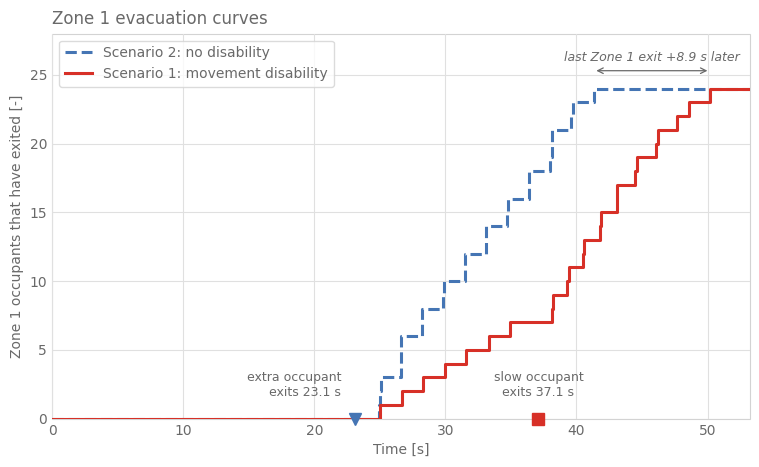

In [11]:
# Figure 1: cumulative Zone 1 exits over time
fig, ax = plt.subplots(figsize=(9, 5), dpi=100)
n1 = len(paired)
t_end = max(paired["exit_s1"].max(), paired["exit_s2"].max()) + 3
for col, color, ls, label in [
    ("exit_s2", C_S2, "--", "Scenario 2: no disability"),
    ("exit_s1", C_S1, "-", "Scenario 1: movement disability"),
]:
    t = np.sort(paired[col].to_numpy())
    ax.step(np.r_[0, t, t_end], np.r_[0, np.arange(1, n1 + 1), n1], where="post",
            color=color, linestyle=ls, linewidth=2.2, label=label)

# Exit time of the extra Zone 2 occupant, marked on the time axis
for t, color, marker, text, dx, ha in [
    (extra_exit, C_S2, "v", f"extra occupant\nexits {extra_exit:.1f} s", -10, "right"),
    (slow_exit, C_S1, "s", f"slow occupant\nexits {slow_exit:.1f} s", 0, "center"),
]:
    ax.plot(t, 0, marker=marker, color=color, markersize=9, clip_on=False, zorder=5)
    ax.annotate(text, (t, 0), xytext=(dx, 14), textcoords="offset points",
                ha=ha, va="bottom", fontsize=9, color="dimgrey")

# Insight: gap between the last Zone 1 exits
last1, last2 = paired["exit_s1"].max(), paired["exit_s2"].max()
ax.annotate("", xy=(last1, n1 + 1.3), xytext=(last2, n1 + 1.3),
            arrowprops={"arrowstyle": "<->", "color": "dimgrey", "lw": 0.9})
ax.text((last1 + last2) / 2, n1 + 1.8, f"last Zone 1 exit {last1 - last2:+.1f} s later",
        ha="center", va="bottom", fontsize=9, color="dimgrey", style="italic")

ax.set_ylim(0, n1 + 4)
ax.set_xlim(0, t_end)
ax.set_xlabel("Time [s]")
ax.set_ylabel("Zone 1 occupants that have exited [-]")
ax.set_title("Zone 1 evacuation curves", loc="left", pad=7)
ax.legend(loc="upper left", **LEGEND)
ax.tick_params(axis="both", which="both", length=0, labelcolor="dimgrey")
frame_axes(ax)
plt.show()

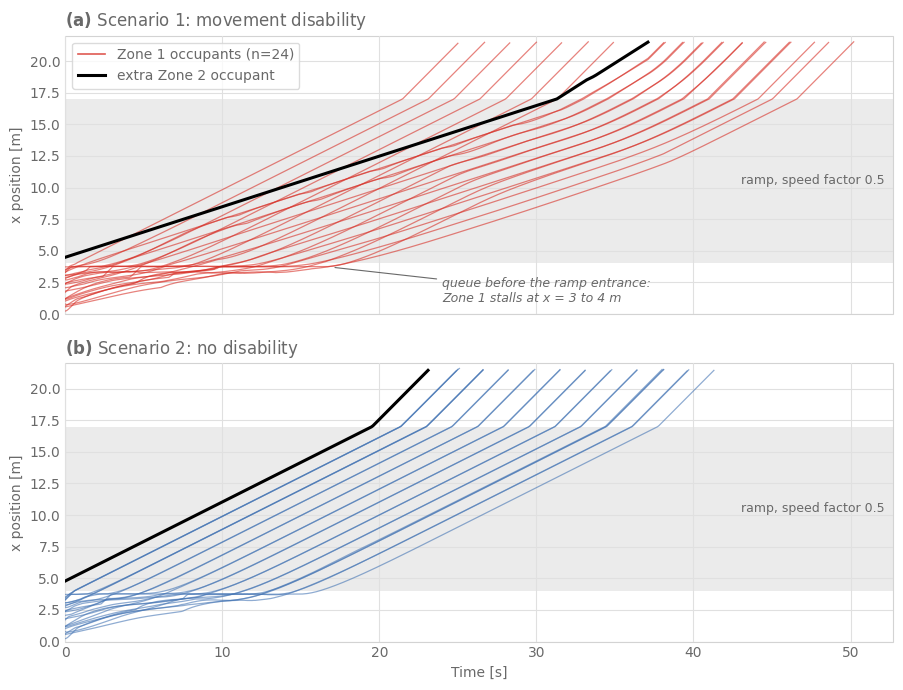

In [12]:
# Figure 2: space-time diagram, x position against time for all agents
xmin, ymin, xmax, ymax = walkable_1.bounds
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True, sharey=True, dpi=100)
for ax, df, color, extra_id, title in [
    (axes[0], df1, C_S1, slow_id, r"$\bf{(a)}$ Scenario 1: movement disability"),
    (axes[1], df2, C_S2, extra_id_s2, r"$\bf{(b)}$ Scenario 2: no disability"),
]:
    ax.axhspan(ramp_x0, ramp_x1, color="lightgrey", alpha=0.45, zorder=0, linewidth=0)
    ax.text(0.99, (ramp_x0 + ramp_x1) / 2, "ramp, speed factor 0.5", transform=ax.get_yaxis_transform(),
            ha="right", va="center", fontsize=9, color="dimgrey")
    for agent_id, traj in df.groupby("id"):
        if agent_id == extra_id:
            continue
        ax.plot(traj["frame"] / frame_rate, traj["x"], color=color, linewidth=0.9, alpha=0.6, zorder=2)
    traj = df[df["id"] == extra_id]
    ax.plot(traj["frame"] / frame_rate, traj["x"], color="black", linewidth=2.2, zorder=4)
    ax.set_title(title, loc="left", pad=7)
    ax.set_ylabel("x position [m]")
    ax.set_ylim(xmin, xmax)
    ax.set_xlim(0, None)
    ax.tick_params(axis="both", which="both", length=0, labelcolor="dimgrey")
    frame_axes(ax)
axes[1].set_xlabel("Time [s]")
axes[0].legend(
    handles=[
        plt.Line2D([], [], color=C_S1, linewidth=1.2, alpha=0.8, label="Zone 1 occupants (n=24)"),
        plt.Line2D([], [], color="black", linewidth=2.2, label="extra Zone 2 occupant"),
    ],
    loc="upper left", **LEGEND,
)
axes[0].annotate("queue before the ramp entrance:\nZone 1 stalls at x = 3 to 4 m",
                 xy=(17, 3.7), xytext=(24, 1.8), ha="left", va="center",
                 fontsize=9, color="dimgrey", style="italic",
                 arrowprops={"arrowstyle": "-", "color": "dimgrey", "lw": 0.8})
plt.tight_layout()
plt.show()

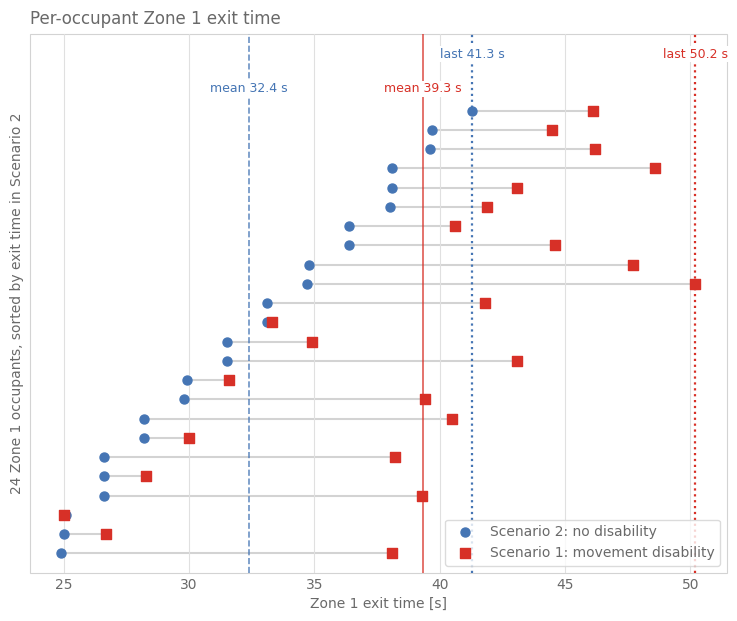

In [13]:
# Figure 3: paired Zone 1 exit times per agent (same spawn position in both scenarios)
order = paired.sort_values("exit_s2").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 7), dpi=100)
y = np.arange(len(order))
ax.hlines(y, order["exit_s2"], order["exit_s1"], color="lightgrey", linewidth=1.5, zorder=1)
ax.scatter(order["exit_s2"], y, color=C_S2, marker="o", s=42, zorder=3, label="Scenario 2: no disability")
ax.scatter(order["exit_s1"], y, color=C_S1, marker="s", s=42, zorder=3, label="Scenario 1: movement disability")

for col, color, ls in [("exit_s2", C_S2, "--"), ("exit_s1", C_S1, "-")]:
    ax.axvline(paired[col].mean(), color=color, linestyle=ls, linewidth=1.2, alpha=0.8, zorder=2)
    ax.axvline(paired[col].max(), color=color, linestyle=":", linewidth=1.6, zorder=2)
    for value, kind, row in [(paired[col].mean(), "mean", 0.0), (paired[col].max(), "last", 1.8)]:
        ax.text(value, len(order) + row - 0.2, f"{kind} {value:.1f} s", ha="center", va="bottom",
                fontsize=9, color=color, bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.0})
ax.set_ylim(-1, len(order) + 3)
ax.set_yticks([])
ax.set_xlabel("Zone 1 exit time [s]")
ax.set_ylabel("24 Zone 1 occupants, sorted by exit time in Scenario 2")
ax.set_title("Per-occupant Zone 1 exit time", loc="left", pad=7)
ax.legend(loc="lower right", **LEGEND)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="both", which="both", length=0, labelcolor="dimgrey")
frame_axes(ax)
plt.show()

## Acceptance

Criterion (ISO 20414 Test 7, NIST TN 1822 Verif.2.10): Zone 1 occupants in Scenario 1 exit later than in Scenario 2. Both the last and the mean Zone 1 exit time must be larger in Scenario 1. Exit time is the last recorded frame divided by the frame rate.

In [14]:
acceptance = pd.DataFrame(
    {
        "Zone 1 last exit (s)": [paired["exit_s1"].max(), paired["exit_s2"].max()],
        "Zone 1 mean exit (s)": [paired["exit_s1"].mean(), paired["exit_s2"].mean()],
    },
    index=["Scenario 1 — movement disability", "Scenario 2 — no disability"],
)
display(acceptance.round(2))

assert paired["exit_s1"].max() > paired["exit_s2"].max(), (
    f"Expected last Zone 1 exit in Scenario 1 ({paired['exit_s1'].max():.2f} s) "
    f"to be later than in Scenario 2 ({paired['exit_s2'].max():.2f} s)."
)
assert paired["exit_s1"].mean() > paired["exit_s2"].mean(), (
    f"Expected mean Zone 1 exit in Scenario 1 ({paired['exit_s1'].mean():.2f} s) "
    f"to be later than in Scenario 2 ({paired['exit_s2'].mean():.2f} s)."
)
result_1.cleanup()
result_2.cleanup();

,Zone 1 last exit (s),Zone 1 mean exit (s)
Scenario 1 — movement disability,50.2,39.32
Scenario 2 — no disability,41.3,32.38
